In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast

In [ ]:
df = pd.read_csv('./MMRDR/MMRDR-CFP/FP.csv')
print("\nShape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nHead:\n", df.head())
print("\nInfo:")
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDescribe:\n", df.describe())


Shape: (11118, 5)

Columns: ['type', 'image', 'grade', 'lesion', 'lr']

Head:
   type             image  grade                 lesion  lr
0   FP  img/tr000001.jpg      0  [0, 0, 0, 0, 0, 0, 0]   0
1   FP  img/tr000002.jpg      3  [1, 1, 1, 0, 0, 0, 0]   1
2   FP  img/tr000003.jpg      2  [1, 1, 1, 0, 0, 0, 0]   0
3   FP  img/tr000004.jpg      1  [1, 0, 0, 0, 0, 0, 0]   1
4   FP  img/tr000005.jpg      0  [0, 0, 0, 0, 0, 0, 0]   0

Info:
<class 'pandas.DataFrame'>
RangeIndex: 11118 entries, 0 to 11117
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   type    11118 non-null  str  
 1   image   11118 non-null  str  
 2   grade   11118 non-null  int64
 3   lesion  11118 non-null  str  
 4   lr      11118 non-null  int64
dtypes: int64(2), str(3)
memory usage: 434.4 KB

Missing values:
 type      0
image     0
grade     0
lesion    0
lr        0
dtype: int64

Describe:
               grade            lr
count  11118.000000  11118.00000

In [3]:
def get_image_type(image_name):
    if image_name.startswith('img/tr'):
        return 'Train'
    elif image_name.startswith('img/ts'):
        return 'Test'
    else:
        return 'Other'

df['image_type'] = df['image'].apply(get_image_type)

In [8]:
# split lesion into 7 columns
lesion_types = ['lesion_1', 'lesion_2', 'lesion_3', 'lesion_4', 'lesion_5', 'lesion_6', 'lesion_7']

lesion_parsed = df['lesion'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
df[lesion_types] = pd.DataFrame(lesion_parsed.tolist(), index=df.index)

print(df[['lesion'] + lesion_types].head())


                  lesion  lesion_1  lesion_2  lesion_3  lesion_4  lesion_5  \
0  [0, 0, 0, 0, 0, 0, 0]         0         0         0         0         0   
1  [1, 1, 1, 0, 0, 0, 0]         1         1         1         0         0   
2  [1, 1, 1, 0, 0, 0, 0]         1         1         1         0         0   
3  [1, 0, 0, 0, 0, 0, 0]         1         0         0         0         0   
4  [0, 0, 0, 0, 0, 0, 0]         0         0         0         0         0   

   lesion_6  lesion_7  
0         0         0  
1         0         0  
2         0         0  
3         0         0  
4         0         0  


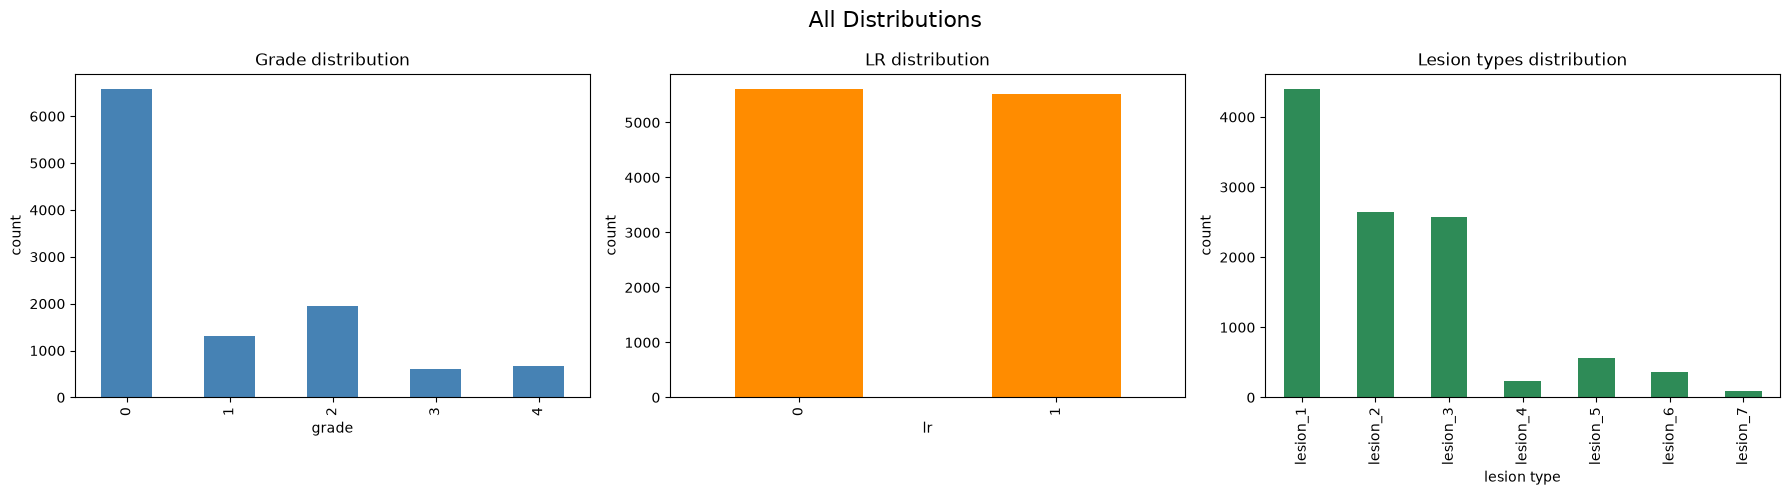

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# grade distribution
df['grade'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Grade distribution')
axes[0].set_xlabel('grade')
axes[0].set_ylabel('count')

# lr distribution
df['lr'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('LR distribution')
axes[1].set_xlabel('lr')
axes[1].set_ylabel('count')

# lesion types distribution (count of positive samples per lesion type)
df[lesion_types].sum().plot(kind='bar', ax=axes[2], color='seagreen')
axes[2].set_title('Lesion types distribution')
axes[2].set_xlabel('lesion type')
axes[2].set_ylabel('count')

plt.suptitle('All Distributions', fontsize=16)
plt.tight_layout()
plt.show()


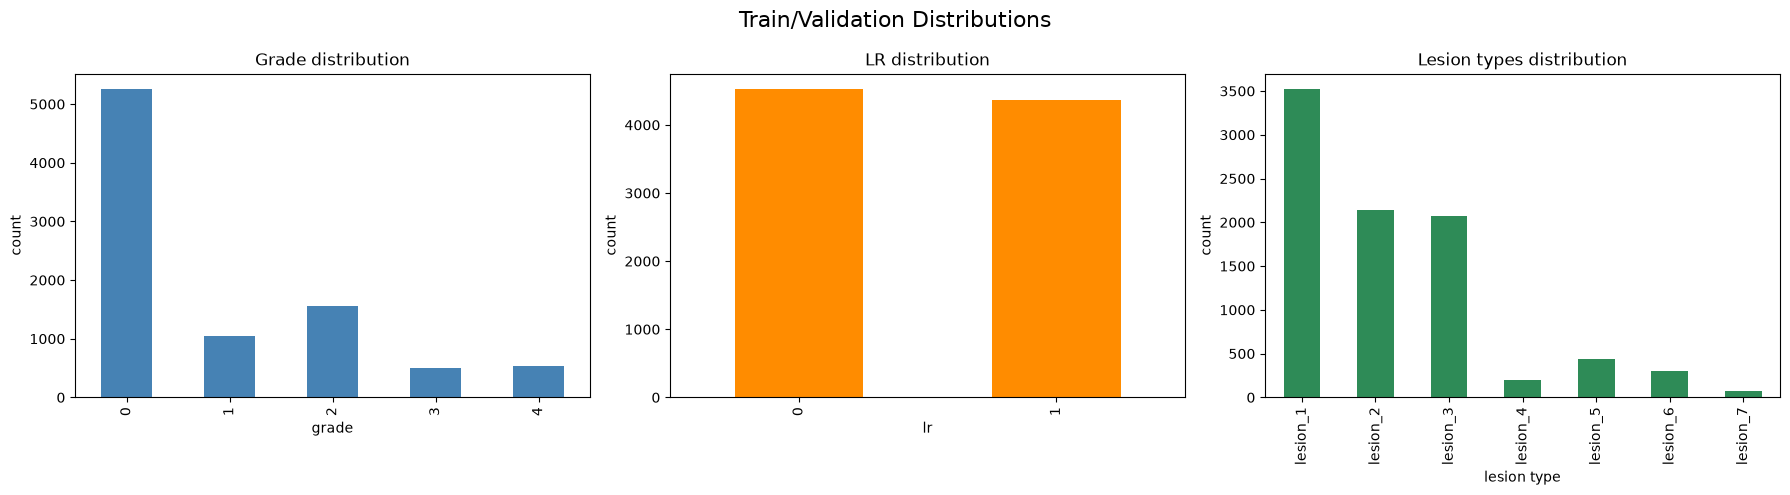

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df_train = df[df['image_type'] == 'Train']
# grade distribution
df_train['grade'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Grade distribution')
axes[0].set_xlabel('grade')
axes[0].set_ylabel('count')

# lr distribution
df_train['lr'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('LR distribution')
axes[1].set_xlabel('lr')
axes[1].set_ylabel('count')

# lesion types distribution (count of positive samples per lesion type)
df_train[lesion_types].sum().plot(kind='bar', ax=axes[2], color='seagreen')
axes[2].set_title('Lesion types distribution')
axes[2].set_xlabel('lesion type')
axes[2].set_ylabel('count')

plt.suptitle('Train/Validation Distributions', fontsize=16)
plt.tight_layout()
plt.show()



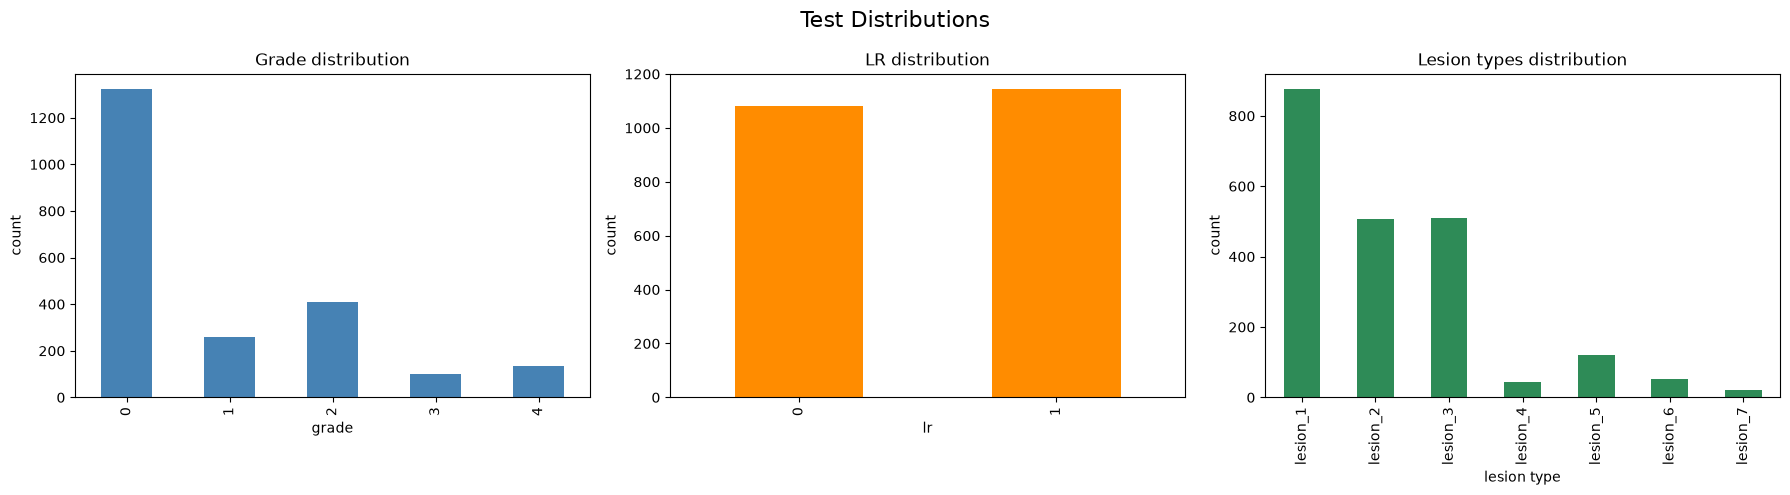

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df_test = df[df['image_type'] == 'Test']
# grade distribution
df_test['grade'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Grade distribution')
axes[0].set_xlabel('grade')
axes[0].set_ylabel('count')

# lr distribution
df_test['lr'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('LR distribution')
axes[1].set_xlabel('lr')
axes[1].set_ylabel('count')

# lesion types distribution (count of positive samples per lesion type)
df_test[lesion_types].sum().plot(kind='bar', ax=axes[2], color='seagreen')
axes[2].set_title('Lesion types distribution')
axes[2].set_xlabel('lesion type')
axes[2].set_ylabel('count')

plt.suptitle('Test Distributions', fontsize=16)
plt.tight_layout()
plt.show()

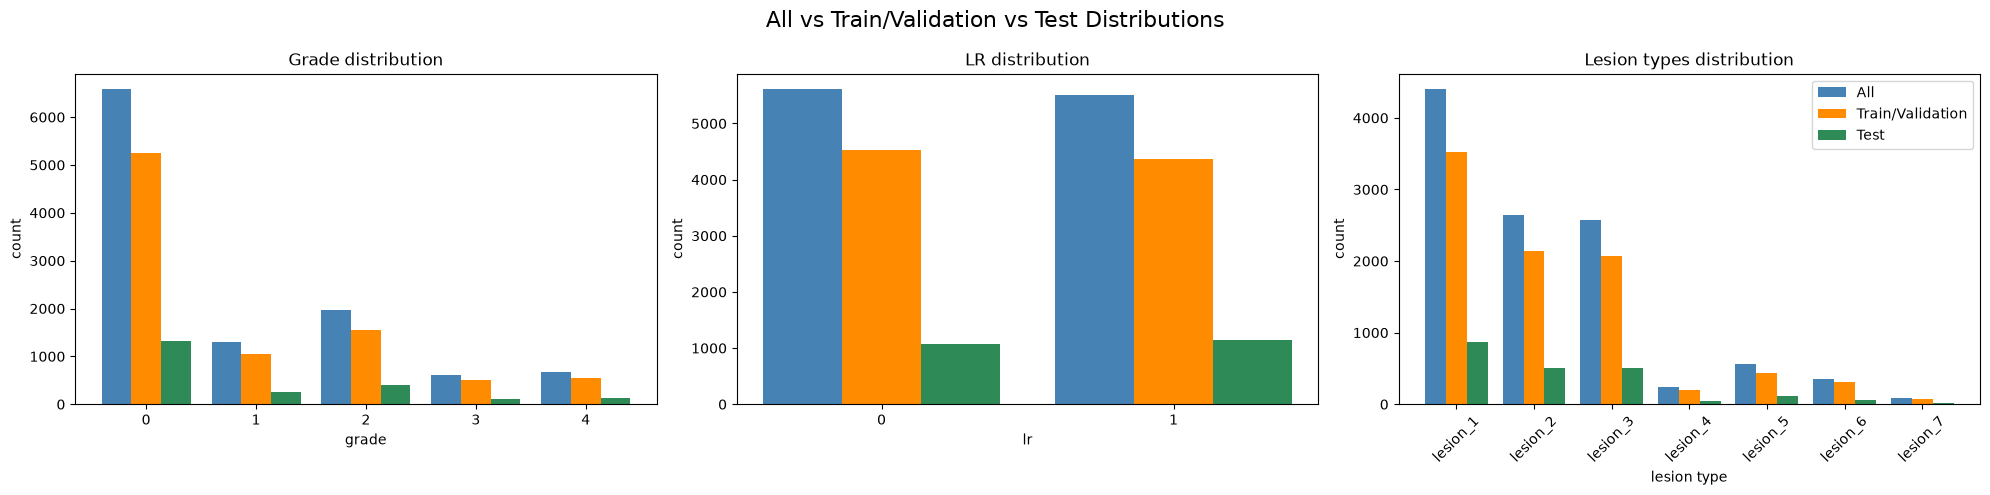

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
width = 0.27

datasets = [('All', df, 'steelblue'), ('Train/Validation', df_train, 'darkorange'), ('Test', df_test, 'seagreen')]

# grade distribution
grade_idx = sorted(df['grade'].unique())
x = np.arange(len(grade_idx))
for i, (label, data, color) in enumerate(datasets):
    counts = data['grade'].value_counts().reindex(grade_idx, fill_value=0)
    axes[0].bar(x + (i - 1) * width, counts.values, width, label=label, color=color)
axes[0].set_xticks(x)
axes[0].set_xticklabels(grade_idx)
axes[0].set_title('Grade distribution')
axes[0].set_xlabel('grade')
axes[0].set_ylabel('count')
# axes[0].legend()

# lr distribution
lr_idx = sorted(df['lr'].unique())
x = np.arange(len(lr_idx))
for i, (label, data, color) in enumerate(datasets):
    counts = data['lr'].value_counts().reindex(lr_idx, fill_value=0)
    axes[1].bar(x + (i - 1) * width, counts.values, width, label=label, color=color)
axes[1].set_xticks(x)
axes[1].set_xticklabels(lr_idx)
axes[1].set_title('LR distribution')
axes[1].set_xlabel('lr')
axes[1].set_ylabel('count')
# axes[1].legend()

# lesion types distribution
x = np.arange(len(lesion_types))
for i, (label, data, color) in enumerate(datasets):
    axes[2].bar(x + (i - 1) * width, data[lesion_types].sum().values, width, label=label, color=color)
axes[2].set_xticks(x)
axes[2].set_xticklabels(lesion_types, rotation=45)
axes[2].set_title('Lesion types distribution')
axes[2].set_xlabel('lesion type')
axes[2].set_ylabel('count')
axes[2].legend()

plt.suptitle('All vs Train/Validation vs Test Distributions', fontsize=16)
plt.tight_layout()
plt.show()